# Project Name
#Paisabazaar Credit Score Classification

Project Type: Exploratory Data Analysis and Classification

**Contribution:** Individual Project

# Project Summary

This project explores customer financial data and develops a machine learning model to classify credit scores into Good, Standard, and Poor categories. The dataset contains 100,000 records and 28 columns describing customer income, outstanding debt, credit history, payment behaviour, and other financial indicators.

The project includes data inspection, missing-value and duplicate checks, exploratory data analysis, visualization, preprocessing, model training, and performance evaluation. Random Forest and Logistic Regression were evaluated, with Random Forest achieving an accuracy of 68.91% in the current experiment.

The analysis identifies important predictive features and examines the relationship between financial characteristics and credit score categories. The results can support exploratory creditworthiness analysis, but should not be treated as a validated lending or fraud detection system.

# GitHub Link

To be added after publishing the project repository.

# Problem Statement

The objective is to analyze customer financial information and predict the credit score category using machine learning. The project aims to identify patterns in income, debt, payment behaviour, credit history, and other features that are associated with credit score classifications.


In [35]:
# Importing Required Libraries

In [36]:
import pandas as pd
import numpy as np

In [37]:
file_path = "/content/drive/MyDrive/Labmentix_Internship_Project/Datasets/bank_customers.csv"

In [38]:
df = pd.read_csv(file_path)   # Loading the Dataset

In [39]:
# Data Inspection

In [40]:
print("Dataset Shape:", df.shape)

Dataset Shape: (100000, 28)


In [41]:
display(df.head())

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,5634,3392,1,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,26.822620,265.0,No,49.574949,21.46538,High_spent_Small_value_payments,312.494089,Good
1,5635,3392,2,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,31.944960,266.0,No,49.574949,21.46538,Low_spent_Large_value_payments,284.629162,Good
2,5636,3392,3,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,28.609352,267.0,No,49.574949,21.46538,Low_spent_Medium_value_payments,331.209863,Good
3,5637,3392,4,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,31.377862,268.0,No,49.574949,21.46538,Low_spent_Small_value_payments,223.451310,Good
4,5638,3392,5,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,24.797347,269.0,No,49.574949,21.46538,High_spent_Medium_value_payments,341.489231,Good


In [42]:
display(df.tail())

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
99995,155625,37932,4,Nicks,25.0,78735990.0,Mechanic,39628.99,3359.415833,4.0,...,Good,502.38,34.663572,378.0,No,35.104023,24.028477,High_spent_Large_value_payments,479.866228,Poor
99996,155626,37932,5,Nicks,25.0,78735990.0,Mechanic,39628.99,3359.415833,4.0,...,Good,502.38,40.565631,379.0,No,35.104023,24.028477,High_spent_Medium_value_payments,496.651610,Poor
99997,155627,37932,6,Nicks,25.0,78735990.0,Mechanic,39628.99,3359.415833,4.0,...,Good,502.38,41.255522,380.0,No,35.104023,24.028477,High_spent_Large_value_payments,516.809083,Poor
99998,155628,37932,7,Nicks,25.0,78735990.0,Mechanic,39628.99,3359.415833,4.0,...,Good,502.38,33.638208,381.0,No,35.104023,24.028477,Low_spent_Large_value_payments,319.164979,Standard
99999,155629,37932,8,Nicks,25.0,78735990.0,Mechanic,39628.99,3359.415833,4.0,...,Good,502.38,34.192463,382.0,No,35.104023,24.028477,High_spent_Medium_value_payments,393.673696,Poor


In [43]:
print("\nColumn Names:")
print(df.columns.tolist())


Column Names:
['ID', 'Customer_ID', 'Month', 'Name', 'Age', 'SSN', 'Occupation', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Type_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt', 'Credit_Utilization_Ratio', 'Credit_History_Age', 'Payment_of_Min_Amount', 'Total_EMI_per_month', 'Amount_invested_monthly', 'Payment_Behaviour', 'Monthly_Balance', 'Credit_Score']


In [44]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        100000 non-null  int64  
 1   Customer_ID               100000 non-null  int64  
 2   Month                     100000 non-null  int64  
 3   Name                      100000 non-null  object 
 4   Age                       100000 non-null  float64
 5   SSN                       100000 non-null  float64
 6   Occupation                100000 non-null  object 
 7   Annual_Income             100000 non-null  float64
 8   Monthly_Inhand_Salary     100000 non-null  float64
 9   Num_Bank_Accounts         100000 non-null  float64
 10  Num_Credit_Card           100000 non-null  float64
 11  Interest_Rate             100000 non-null  float64
 12  Num_of_Loan               100000 non-null  float64
 13  Type_of_Loan              100000 non-null  ob

## Dataset Overview

The dataset contains 100,000 customer records and 28 columns. It includes demographic information, income details, credit history, loan information, payment behaviour, and credit score categories.

The target variable is `Credit_Score`, which contains three classes: `Good`, `Standard`, and `Poor`.

### Dataset Inspection

The following operations were performed to understand the dataset:

- `head()` and `tail()` to inspect sample records.
- `shape` and `columns` to identify dataset dimensions and column names.
- `info()` to inspect data types and non-null counts.
- `describe()` to summarize numerical features.
- Duplicate and missing-value checks to assess data quality.

### Data Dictionary

| Column | Description |
|---|---|
| ID | Record identifier |
| Customer_ID | Customer identifier |
| Month | Month associated with the record |
| Name | Customer name |
| Age | Customer age |
| SSN | Social Security Number field |
| Occupation | Customer occupation |
| Annual_Income | Annual income |
| Monthly_Inhand_Salary | Monthly in-hand salary |
| Num_Bank_Accounts | Number of bank accounts |
| Num_Credit_Card | Number of credit cards |
| Interest_Rate | Interest rate value |
| Num_of_Loan | Number of loans |
| Type_of_Loan | Loan types associated with the customer |
| Delay_from_due_date | Delay relative to payment due date |
| Num_of_Delayed_Payment | Number of delayed payments |
| Changed_Credit_Limit | Change in credit limit |
| Num_Credit_Inquiries | Number of credit inquiries |
| Credit_Mix | Credit mix category |
| Outstanding_Debt | Outstanding debt amount |
| Credit_Utilization_Ratio | Credit utilization ratio |
| Credit_History_Age | Length of credit history |
| Payment_of_Min_Amount | Minimum payment status |
| Total_EMI_per_month | Total monthly EMI |
| Amount_invested_monthly | Amount invested monthly |
| Payment_Behaviour | Customer payment behaviour |
| Monthly_Balance | Monthly account balance |
| Credit_Score | Target variable representing the credit score category |


# Data Quality check

In [45]:
print("Duplicate rows:", df.duplicated().sum())

print("\nMissing values per column:")
display(
    df.isnull().sum()
    .sort_values(ascending=False)
    .to_frame(name="Missing_Count")
)

categorical_cols = [
    "Occupation",
    "Credit_Mix",
    "Payment_of_Min_Amount",
    "Payment_Behaviour",
    "Credit_Score"
]

for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).head(15))


Duplicate rows: 0

Missing values per column:


,Missing_Count
ID,0
Customer_ID,0
Month,0
Name,0
Age,0
SSN,0
Occupation,0
Annual_Income,0
Monthly_Inhand_Salary,0
Num_Bank_Accounts,0



Occupation:
Occupation
Lawyer           7096
Engineer         6864
Architect        6824
Mechanic         6776
Accountant       6744
Scientist        6744
Media_Manager    6720
Developer        6720
Teacher          6672
Entrepreneur     6648
Doctor           6568
Journalist       6536
Manager          6432
Musician         6352
Writer           6304
Name: count, dtype: int64

Credit_Mix:
Credit_Mix
Standard    45848
Good        30384
Bad         23768
Name: count, dtype: int64

Payment_of_Min_Amount:
Payment_of_Min_Amount
Yes    52326
No     35667
NM     12007
Name: count, dtype: int64

Payment_Behaviour:
Payment_Behaviour
Low_spent_Small_value_payments      28616
High_spent_Medium_value_payments    19738
High_spent_Large_value_payments     14726
Low_spent_Medium_value_payments     14399
High_spent_Small_value_payments     11764
Low_spent_Large_value_payments      10757
Name: count, dtype: int64

Credit_Score:
Credit_Score
Standard    53174
Poor        28998
Good        17828
Name: c

In [46]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
ID,100000.0,8.063150e+04,4.330149e+04,5634.000000,4.313275e+04,8.063150e+04,1.181302e+05,1.556290e+05
Customer_ID,100000.0,2.598267e+04,1.434054e+04,1006.000000,1.366450e+04,2.577700e+04,3.838500e+04,5.099900e+04
Month,100000.0,4.500000e+00,2.291299e+00,1.000000,2.750000e+00,4.500000e+00,6.250000e+00,8.000000e+00
Age,100000.0,3.331634e+01,1.076481e+01,14.000000,2.400000e+01,3.300000e+01,4.200000e+01,5.600000e+01
SSN,100000.0,5.004617e+08,2.908267e+08,81349.000000,2.451686e+08,5.006886e+08,7.560027e+08,9.999934e+08
Annual_Income,100000.0,5.050512e+04,3.829942e+04,7005.930000,1.934297e+04,3.699971e+04,7.168347e+04,1.799873e+05
Monthly_Inhand_Salary,100000.0,4.197271e+03,3.186432e+03,303.645417,1.626594e+03,3.095905e+03,5.957715e+03,1.520463e+04
Num_Bank_Accounts,100000.0,5.368820e+00,2.593314e+00,0.000000,3.000000e+00,5.000000e+00,7.000000e+00,1.100000e+01
Num_Credit_Card,100000.0,5.533570e+00,2.067098e+00,0.000000,4.000000e+00,5.000000e+00,7.000000e+00,1.100000e+01
Interest_Rate,100000.0,1.453208e+01,8.741330e+00,1.000000,7.000000e+00,1.300000e+01,2.000000e+01,3.400000e+01


## Data Quality Assessment

Data quality checks were performed to identify duplicate records, missing values, and unusual numerical values.

- Duplicate records were checked using `duplicated()`.
- Missing values were checked for every column using `isnull().sum()`.
- Numerical features were summarized using descriptive statistics.
- Categorical values were inspected to identify frequent categories and special labels.

The initial checks reported zero duplicate rows and zero null values. However, special categorical values such as `NM` should not automatically be treated as missing values. Their meaning requires verification.



# Exploratory Data Analysis (EDA)

In [47]:
df["Credit_Score"].value_counts()

,count
Credit_Score,
Standard,53174
Poor,28998
Good,17828


In [48]:

(df["Credit_Score"].value_counts(normalize=True) * 100).round(2)


,proportion
Credit_Score,
Standard,53.17
Poor,29.00
Good,17.83


In [49]:
# import libraries for visualizaation
import matplotlib.pyplot as plt
import seaborn as sns

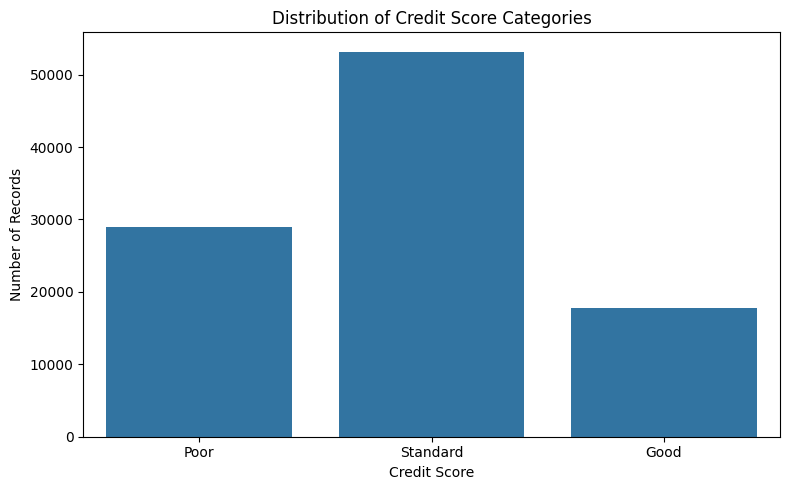

In [50]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Credit_Score",
    order=["Poor", "Standard", "Good"]
)

plt.title("Distribution of Credit Score Categories")
plt.xlabel("Credit Score")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

#### Interpretation

The dataset contains three credit score categories: Good, Standard, and Poor. The Standard category represents the largest proportion of customers, followed by Poor and Good.

- **Standard:** 53.17% of customers
- **Poor:** 29.00% of customers
- **Good:** 17.83% of customers

#### Insight

The dataset has an unequal distribution of credit score categories. The model should therefore be evaluated using precision, recall, and F1-score along with accuracy.

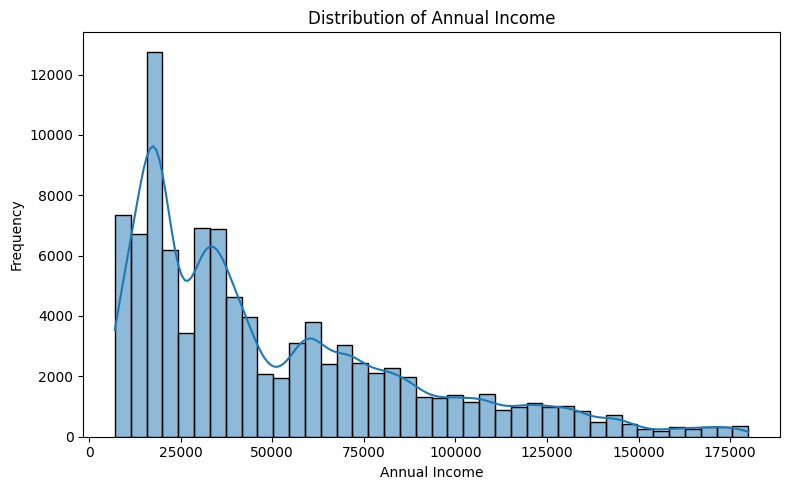

In [51]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Annual_Income",
    bins=40,
    kde=True
)

plt.title("Distribution of Annual Income")
plt.xlabel("Annual Income")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

#### Interpretation

The histogram shows the distribution of annual income among customers. It helps us understand how income values are spread across the dataset and identify whether most customers fall within a particular income range.

#### Insight

Annual income is an important financial feature for credit score analysis. However, its relationship with credit score should be evaluated alongside other factors, such as outstanding debt, interest rate, and payment history.



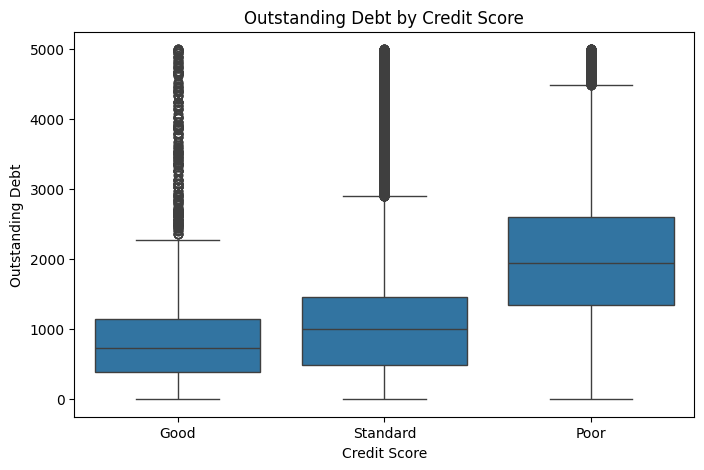

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Credit_Score",
    y="Outstanding_Debt"
)

plt.title("Outstanding Debt by Credit Score")
plt.xlabel("Credit Score")
plt.ylabel("Outstanding Debt")
plt.show()

#### Interpretation

The boxplot compares outstanding debt across the three credit score categories: Good, Standard, and Poor. It displays the median, spread, and potential outliers in outstanding debt for each category.

#### Insight

Comparing outstanding debt across credit score groups helps identify whether debt levels differ between customers with different credit scores. Outstanding debt can be considered alongside other financial features when building a credit score classification model.



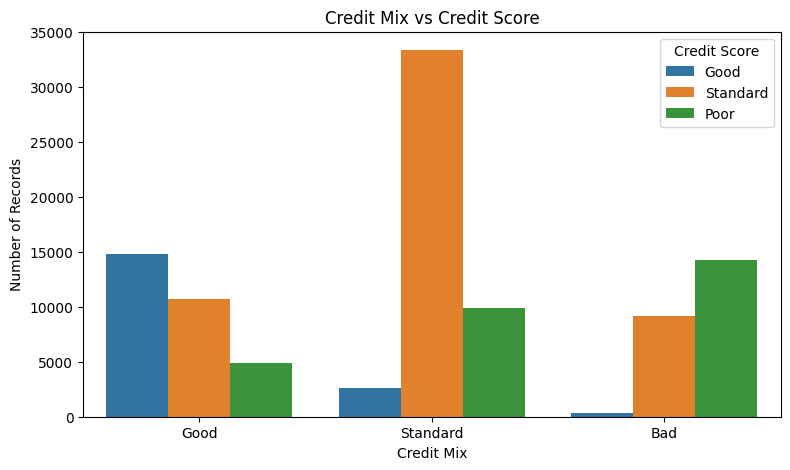

In [53]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Credit_Mix",
    hue="Credit_Score"
)

plt.title("Credit Mix vs Credit Score")
plt.xlabel("Credit Mix")
plt.ylabel("Number of Records")
plt.legend(title="Credit Score")
plt.show()

#### Interpretation

The count plot shows the distribution of credit score categories across different Credit Mix categories. It helps compare how customers with different credit mix values are represented in the Good, Standard, and Poor credit score groups.

#### Insight

Credit Mix may provide useful information about a customer's credit profile. The observed distribution can help identify patterns between credit mix categories and credit score, although the plot alone does not establish a causal relationship.



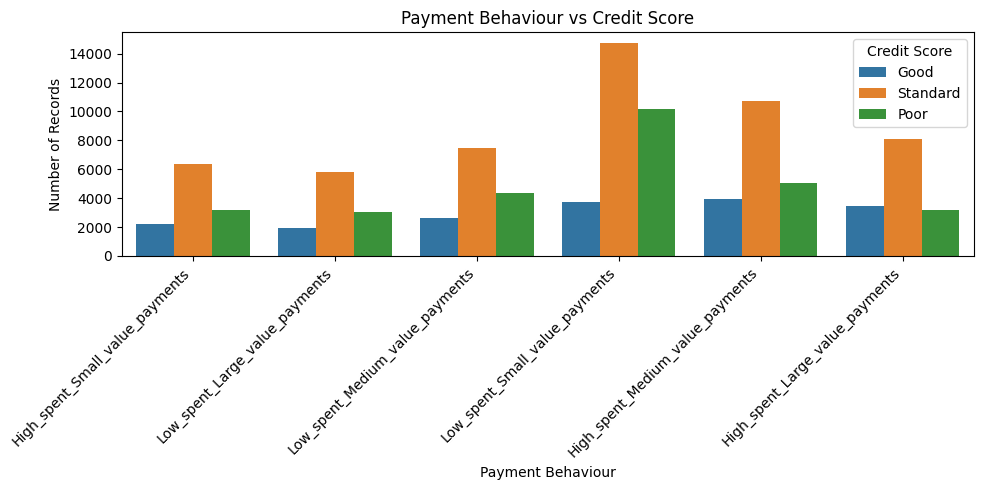

In [54]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Payment_Behaviour",
    hue="Credit_Score"
)

plt.title("Payment Behaviour vs Credit Score")
plt.xlabel("Payment Behaviour")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Credit Score")
plt.tight_layout()
plt.show()

#### Interpretation

The count plot compares customer payment behaviour across the Good, Standard, and Poor credit score categories. It helps examine how different payment behaviour categories are distributed among customers with different credit scores.

#### Insight

Payment behaviour may provide useful information for credit score classification. Comparing these categories can help identify patterns in the dataset and determine whether payment behaviour is a useful feature for predicting credit scores.



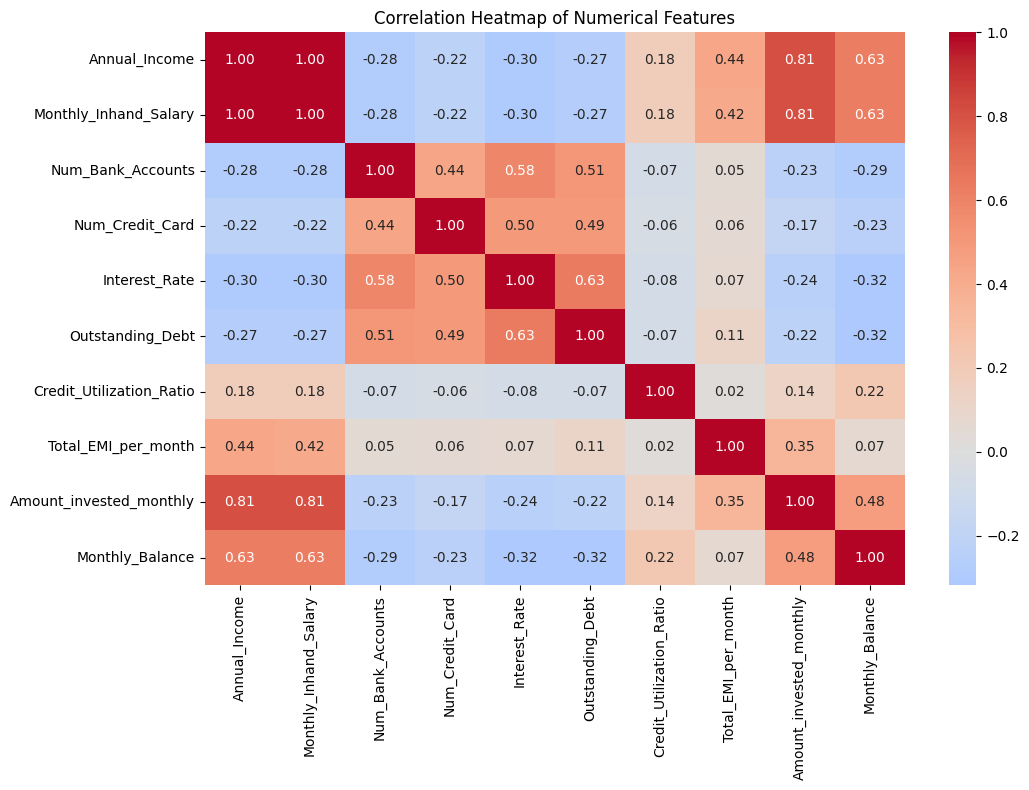

In [55]:
numeric_cols = [
    "Annual_Income",
    "Monthly_Inhand_Salary",
    "Num_Bank_Accounts",
    "Num_Credit_Card",
    "Interest_Rate",
    "Outstanding_Debt",
    "Credit_Utilization_Ratio",
    "Total_EMI_per_month",
    "Amount_invested_monthly",
    "Monthly_Balance"
]

plt.figure(figsize=(11, 8))

correlation = df[numeric_cols].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

#### Interpretation

The correlation heatmap shows the strength and direction of relationships between numerical features in the dataset. Values closer to +1 indicate a strong positive correlation, values closer to -1 indicate a strong negative correlation, and values near 0 indicate a weak linear relationship.

#### Key Observations

- Annual Income and Monthly In-hand Salary have a very strong positive correlation.
- Annual Income and Amount Invested Monthly also show a strong positive correlation.
- Interest Rate and Outstanding Debt have a moderately strong positive correlation.
- Number of Bank Accounts and Interest Rate show a positive correlation.

#### Insight

Highly correlated features may contain overlapping information. These relationships should be considered during feature analysis, but correlation does not imply causation.

In [56]:
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing_Values": missing_values,
    "Missing_Percentage": (missing_values / len(df)) * 100
})

missing_summary = missing_summary[
    missing_summary["Missing_Values"] > 0
].sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(missing_summary)

,Missing_Values,Missing_Percentage


## Data Quality Assessment

The dataset was examined to identify missing values and duplicate records before model development.

### Findings

- **Missing values:** The initial null-value check did not identify any missing values.
- **Duplicate records:** No duplicate rows were found during the initial inspection.
- **Special categorical values:** Some fields contain values such as `NM` and `No Data`. These are stored as text values and may represent unknown or unavailable information.
- **Data preprocessing:** Numerical and categorical features are handled separately using imputation and encoding pipelines.

### Conclusion

Although no standard null values were detected, special text values should be reviewed before modelling. Their meaning should be verified against the dataset documentation before deciding whether to replace them or retain them as separate categories.

In [57]:
for col in df.select_dtypes(include="object").columns:
    print(f"\n{col}:")
    print(df[col].value_counts().head(10))


Name:
Name
Jessicad            48
Langep              48
Stevex              48
Ronald Groverk      40
Johnc               40
Phila               40
Raymondr            40
Nate Raymondw       40
Kimj                40
Ryan Vlastelicad    40
Name: count, dtype: int64

Occupation:
Occupation
Lawyer           7096
Engineer         6864
Architect        6824
Mechanic         6776
Accountant       6744
Scientist        6744
Media_Manager    6720
Developer        6720
Teacher          6672
Entrepreneur     6648
Name: count, dtype: int64

Type_of_Loan:
Type_of_Loan
No Data                    11408
Not Specified               1408
Credit-Builder Loan         1280
Personal Loan               1272
Debt Consolidation Loan     1264
Student Loan                1240
Payday Loan                 1200
Mortgage Loan               1176
Auto Loan                   1152
Home Equity Loan            1136
Name: count, dtype: int64

Credit_Mix:
Credit_Mix
Standard    45848
Good        30384
Bad         23768


In [58]:
for col in ["Type_of_Loan", "Payment_of_Min_Amount"]:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False).head(15))

display(df.describe().T)


Type_of_Loan
Type_of_Loan
No Data                                  11408
Not Specified                             1408
Credit-Builder Loan                       1280
Personal Loan                             1272
Debt Consolidation Loan                   1264
Student Loan                              1240
Payday Loan                               1200
Mortgage Loan                             1176
Auto Loan                                 1152
Home Equity Loan                          1136
Personal Loan, and Student Loan            320
Not Specified, and Payday Loan             272
Mortgage Loan, and Home Equity Loan        264
Student Loan, and Payday Loan              256
Student Loan, and Credit-Builder Loan      248
Name: count, dtype: int64

Payment_of_Min_Amount
Payment_of_Min_Amount
Yes    52326
No     35667
NM     12007
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
ID,100000.0,8.063150e+04,4.330149e+04,5634.000000,4.313275e+04,8.063150e+04,1.181302e+05,1.556290e+05
Customer_ID,100000.0,2.598267e+04,1.434054e+04,1006.000000,1.366450e+04,2.577700e+04,3.838500e+04,5.099900e+04
Month,100000.0,4.500000e+00,2.291299e+00,1.000000,2.750000e+00,4.500000e+00,6.250000e+00,8.000000e+00
Age,100000.0,3.331634e+01,1.076481e+01,14.000000,2.400000e+01,3.300000e+01,4.200000e+01,5.600000e+01
SSN,100000.0,5.004617e+08,2.908267e+08,81349.000000,2.451686e+08,5.006886e+08,7.560027e+08,9.999934e+08
Annual_Income,100000.0,5.050512e+04,3.829942e+04,7005.930000,1.934297e+04,3.699971e+04,7.168347e+04,1.799873e+05
Monthly_Inhand_Salary,100000.0,4.197271e+03,3.186432e+03,303.645417,1.626594e+03,3.095905e+03,5.957715e+03,1.520463e+04
Num_Bank_Accounts,100000.0,5.368820e+00,2.593314e+00,0.000000,3.000000e+00,5.000000e+00,7.000000e+00,1.100000e+01
Num_Credit_Card,100000.0,5.533570e+00,2.067098e+00,0.000000,4.000000e+00,5.000000e+00,7.000000e+00,1.100000e+01
Interest_Rate,100000.0,1.453208e+01,8.741330e+00,1.000000,7.000000e+00,1.300000e+01,2.000000e+01,3.400000e+01


# Feature Selection and Preprocessing

In [59]:
target = "Credit_Score"

drop_cols = ["ID", "Name", "SSN", "Credit_Score"]

X = df.drop(columns=drop_cols)
y = df[target]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (100000, 24)
Target shape: (100000,)


#Train-Test Split

In [60]:
from sklearn.model_selection import GroupShuffleSplit

groups = df["Customer_ID"]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].drop(columns=["Customer_ID"])
X_test = X.iloc[test_idx].drop(columns=["Customer_ID"])

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 80000
Testing records: 20000


Categorical Features Encoding

In [61]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

categorical_cols = X_train.select_dtypes(include="object").columns
numeric_cols = X_train.select_dtypes(exclude="object").columns

preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols)
])

# Model Training, Testing & Evaluation

In [62]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.6891

Classification Report:
              precision    recall  f1-score   support

        Good       0.55      0.63      0.59      3563
        Poor       0.70      0.65      0.68      5813
    Standard       0.74      0.73      0.73     10624

    accuracy                           0.69     20000
   macro avg       0.66      0.67      0.67     20000
weighted avg       0.69      0.69      0.69     20000



## Model Evaluation

The Random Forest classifier was evaluated on the test dataset to measure its ability to classify customers into Good, Standard, and Poor credit score categories.

### Evaluation Results

- **Accuracy:** 68.91%
- **Macro F1-score:** 0.67
- **Weighted F1-score:** Approximately 0.69

### Class-wise Performance

| Credit Score | Precision | Recall | F1-score |
|---|---:|---:|---:|
| Good | 0.55 | 0.63 | 0.59 |
| Poor | 0.70 | 0.65 | 0.68 |
| Standard | 0.74 | 0.73 | 0.73 |

### Interpretation

The model achieved an accuracy of 68.91% on the test dataset. It performed best on the Standard category based on F1-score, while the Good category had the lowest F1-score.

The macro F1-score provides an average across the three categories, giving each class equal weight. The weighted F1-score accounts for the number of test samples in each class.

### Conclusion

The Random Forest model provides a baseline for credit score classification. Further improvements could include hyperparameter tuning, feature analysis, and comparison with other classification algorithms.

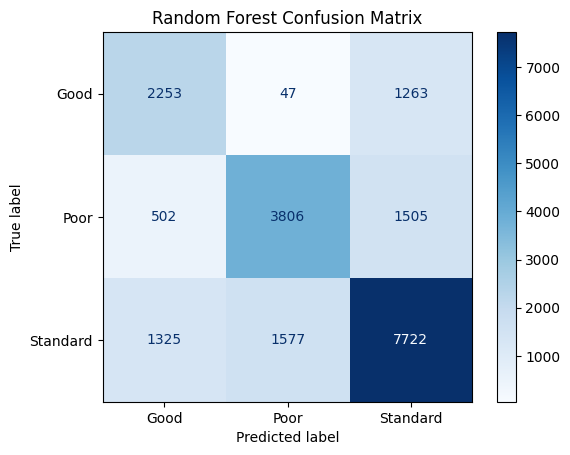

In [63]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    labels=["Good", "Poor", "Standard"],
    cmap="Blues"
)

plt.title("Random Forest Confusion Matrix")
plt.show()

In [64]:
import matplotlib.pyplot as plt

feature_names = model.named_steps["preprocessing"].get_feature_names_out()
importances = model.named_steps["classifier"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(importance_df.head(10))

,Feature,Importance
12,num__Outstanding_Debt,0.062231
14,num__Credit_History_Age,0.051710
6,num__Interest_Rate,0.051104
8,num__Delay_from_due_date,0.043971
17,num__Monthly_Balance,0.040442
10,num__Changed_Credit_Limit,0.039712
11,num__Num_Credit_Inquiries,0.038193
13,num__Credit_Utilization_Ratio,0.037203
9,num__Num_of_Delayed_Payment,0.035963
0,num__Month,0.033372


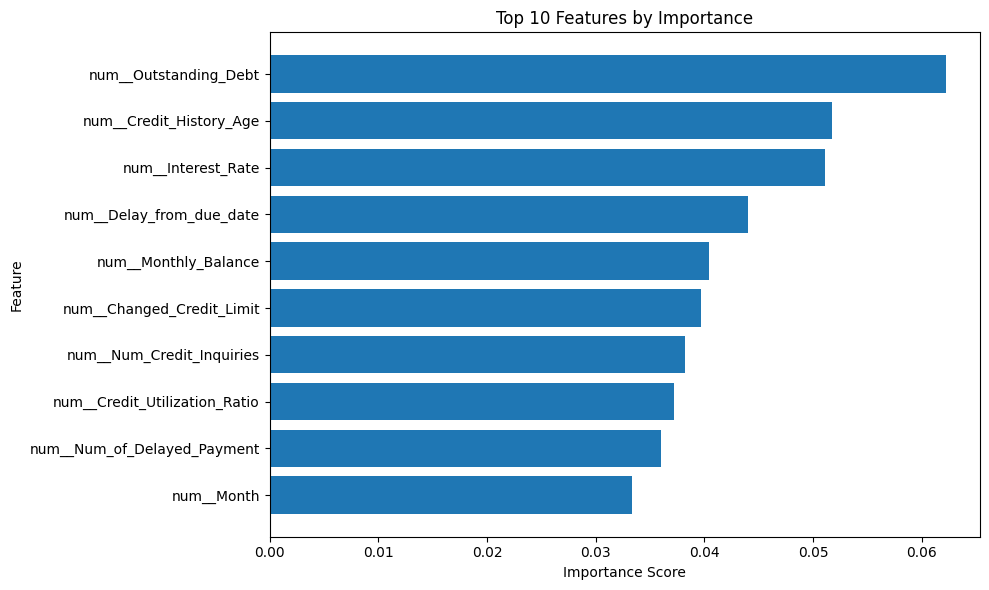

In [65]:
# Plot the top 10 important features
top_features = importance_df.head(10).sort_values("Importance")

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 10 Features by Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## Feature Importance Analysis

Feature importance was examined to identify the variables that contributed most to the Random Forest model's predictions.

### Key Findings

The leading features identified by the model were:

- Outstanding_Debt
- Credit_History_Age
- Interest_Rate
- Delay_from_due_date
- Monthly_Balance
- Changed_Credit_Limit
- Num_Credit_Inquiries
- Credit_Utilization_Ratio
- Num_of_Delayed_Payment
- Month

### Interpretation

Outstanding debt, credit history age, and interest rate were among the most important features in the model. This suggests that information about a customer's debt and credit history helped the classifier distinguish between credit score categories.

### Limitation

Feature importance indicates how much a feature contributes to the model's predictions under its importance measure. It does not establish that the feature causes a particular credit score or that the relationship is causal.

## Class-Weighted Random Forest Model

In [66]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report

balanced_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

balanced_model.fit(X_train, y_train)
balanced_pred = balanced_model.predict(X_test)

print("Balanced Model Accuracy:",
      round(accuracy_score(y_test, balanced_pred), 4))

print("Balanced Model Macro F1:",
      round(f1_score(y_test, balanced_pred, average="macro"), 4))

print("\nClassification Report:")
print(classification_report(y_test, balanced_pred))

Balanced Model Accuracy: 0.6825
Balanced Model Macro F1: 0.6583

Classification Report:
              precision    recall  f1-score   support

        Good       0.55      0.61      0.58      3563
        Poor       0.69      0.66      0.68      5813
    Standard       0.73      0.72      0.72     10624

    accuracy                           0.68     20000
   macro avg       0.66      0.66      0.66     20000
weighted avg       0.69      0.68      0.68     20000



## Model Comparison

Two Random Forest configurations were evaluated using the same train-test split.

| Model | Accuracy | Macro F1-score |
|---|---:|---:|
| Standard Random Forest | 68.91% | 0.67 |
| Class-weighted Random Forest | 68.25% | 0.6583 |

The standard Random Forest achieved higher accuracy and macro F1-score in this experiment. Class weighting did not improve the overall metrics. Further experiments may help improve the model's performance across all credit score categories.

## Final Conclusion

This project focused on analysing customer financial data and developing a machine learning model to classify credit scores into Good, Standard, and Poor categories.

Exploratory Data Analysis helped examine credit score distribution, annual income, outstanding debt, credit mix, payment behaviour, and relationships between numerical features.

A Random Forest classifier achieved **68.91% accuracy** and a **macro F1-score of 0.67** on the test dataset. The model performed better on the Standard category than on the Good category, indicating that classification performance varies across classes.

Overall, the project demonstrates how data analysis and machine learning can be applied to credit score classification. The results provide a baseline for further model improvement.

## Future Improvements

- Perform hyperparameter tuning to improve model performance.
- Compare Random Forest with other classification algorithms.
- Review special categorical values such as `NM` and `No Data`.
- Evaluate class-wise precision, recall, and F1-score to identify weaknesses.
- Investigate feature redundancy and improve feature selection.
- Validate the model on additional data before considering real-world use.

## Project Limitation

The model predicts credit score categories; it does not directly detect banking fraud. Its predictions are based on the available dataset and should not be treated as the sole basis for real financial decisions.